# News Category Classification — Training Notebook

**Model:** Bidirectional LSTM with GloVe 100d embeddings  
**Dataset:** HuffPost News Category Dataset (~210K articles, 42 categories)  
**Framework:** PyTorch

In [1]:
# ══════════════════════════════════════════════════════════════
#  Cell 1 — Imports & Reproducibility
# ══════════════════════════════════════════════════════════════
import os
import re
import string
import pickle
import zipfile
import logging
import urllib.request
import random
import json
from collections import Counter
from pathlib import Path
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import nltk
for resource, pkg in [
    ("tokenizers/punkt", "punkt"),
    ("tokenizers/punkt_tab", "punkt_tab"),
    ("corpora/stopwords", "stopwords"),
]:
    try:
        nltk.data.find(resource)
    except LookupError:
        nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords as nltk_stopwords
from nltk.tokenize import word_tokenize

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.model_selection import train_test_split

# ── Reproducibility ───────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")

# ── Logging ───────────────────────────────────────────────────
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    datefmt="%H:%M:%S",
    handlers=[
        logging.FileHandler("training.log", mode="w"),
        logging.StreamHandler()
    ]
)
logger = logging.getLogger("Train")
print("✅ Imports done.")

Device : cpu
✅ Imports done.


In [2]:
# ══════════════════════════════════════════════════════════════
#  Cell 2 — Configuration
# ══════════════════════════════════════════════════════════════
CONFIG = {
    # ── Paths ─────────────────────────────────────────────────
    "data_dir"            : Path("data"),
    "glove_dir"           : Path("data/glove"),
    "dataset_file"        : Path("data/news_category_dataset.csv"),
    "glove_url"           : "https://nlp.stanford.edu/data/glove.6B.zip",
    "glove_zip"           : Path("data/glove/glove.6B.zip"),
    "glove_file"          : Path("data/glove/glove.6B.100d.txt"),
    "model_save_path"     : Path("saved_model.pth"),
    "word2idx_save_path"  : Path("models/word2idx.pkl"),
    "label_enc_save_path" : Path("models/label_encoder.pkl"),

    # ── Data splits ───────────────────────────────────────────
    "train_ratio"         : 0.80,
    "val_ratio"           : 0.10,
    "test_ratio"          : 0.10,
    "random_seed"         : SEED,

    # ── Vocab & sequence ──────────────────────────────────────
    "max_vocab_size"      : 25_000,
    "max_seq_len"         : 256,
    "min_word_freq"       : 2,

    # ── Model architecture ────────────────────────────────────
    "embed_dim"           : 100,
    "fine_tune_embeddings": True,
    "hidden_size"         : 128,
    "num_layers"          : 2,
    "bidirectional"       : True,
    "lstm_dropout"        : 0.5,
    "fc_dropout"          : 0.3,

    # ── Training ──────────────────────────────────────────────
    "epochs"              : 20,
    "batch_size"          : 64,
    "learning_rate"       : 1e-3,
    "weight_decay"        : 1e-4,
    "grad_clip"           : 1.0,
    "early_stop_patience" : 5,
    "scheduler_T_max"     : 20,
}

# Create directories
CONFIG["data_dir"].mkdir(parents=True, exist_ok=True)
CONFIG["glove_dir"].mkdir(parents=True, exist_ok=True)
Path("models").mkdir(parents=True, exist_ok=True)
print(" Config ready.")

 Config ready.


In [3]:
# ══════════════════════════════════════════════════════════════
#  Cell 3 — Load & Prepare Dataset
# ══════════════════════════════════════════════════════════════
df = pd.read_csv(CONFIG["dataset_file"])
print(f"Raw dataset: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

# ── Standardise column names ──────────────────────────────────
df.columns = [c.strip().lower() for c in df.columns]

# If the file has 'headline'/'short_description' instead of 'text', combine them
if "text" not in df.columns and "headline" in df.columns:
    df["text"] = df["headline"].fillna("") + " " + df["short_description"].fillna("")
    print("Created 'text' column from headline + short_description.")

# Use category column directly as the label
df["label"] = df["category"]

# Drop any rows with missing text or label
df.dropna(subset=["text", "label"], inplace=True)
df = df[df["text"].str.strip().astype(bool)]  # drop empty strings
df.reset_index(drop=True, inplace=True)

print(f"\nCleaned dataset: {len(df):,} rows")
print(f"Number of categories: {df['label'].nunique()}")
print(f"\nCategory distribution:")
print(df["label"].value_counts())

Raw dataset: (209527, 2)
Columns: ['text', 'category']

Cleaned dataset: 209,522 rows
Number of categories: 42

Category distribution:
label
POLITICS          35601
WELLNESS          17945
ENTERTAINMENT     17362
TRAVEL             9900
STYLE & BEAUTY     9814
PARENTING          8791
HEALTHY LIVING     6694
QUEER VOICES       6346
FOOD & DRINK       6340
BUSINESS           5991
COMEDY             5400
SPORTS             5077
BLACK VOICES       4583
HOME & LIVING      4320
PARENTS            3955
THE WORLDPOST      3664
WEDDINGS           3653
WOMEN              3572
CRIME              3562
IMPACT             3484
DIVORCE            3426
WORLD NEWS         3299
MEDIA              2943
WEIRD NEWS         2777
GREEN              2622
WORLDPOST          2578
RELIGION           2577
STYLE              2254
SCIENCE            2206
TECH               2104
TASTE              2096
MONEY              1756
ARTS               1509
ENVIRONMENT        1444
FIFTY              1401
GOOD NEWS          

In [4]:
# ══════════════════════════════════════════════════════════════
#  Cell 4 — Text Preprocessing & Tokenisation
# ══════════════════════════════════════════════════════════════
STOP_WORDS = set(nltk_stopwords.words("english"))
PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"
PAD_IDX, UNK_IDX = 0, 1

def clean_text(text: str) -> str:
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", "", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", "", text)
    return re.sub(r"\s+", " ", text).strip()

def tokenize_text(text: str) -> List[str]:
    tokens = word_tokenize(text)
    return [t for t in tokens if t not in STOP_WORDS and len(t) > 1]

def preprocess(text: str) -> List[str]:
    return tokenize_text(clean_text(text))

def text_to_indices(tokens: List[str], word2idx: Dict, max_len: int) -> List[int]:
    indices = [word2idx.get(t, UNK_IDX) for t in tokens[:max_len]]
    return indices + [PAD_IDX] * (max_len - len(indices))

print("⏳ Preprocessing text (this may take a few minutes on 210K articles) ...")
df["tokens"] = df["text"].apply(preprocess)
print(f"✅ Preprocessing done.")

⏳ Preprocessing text (this may take a few minutes on 210K articles) ...
✅ Preprocessing done.


In [5]:
# ══════════════════════════════════════════════════════════════
#  Cell 5 — Label Encoding & Train/Val/Test Split
# ══════════════════════════════════════════════════════════════

# ── Encode labels dynamically from whatever categories exist ──
unique_classes = sorted(df["label"].unique())
NUM_CLASSES = len(unique_classes)
STR2IDX: Dict[str, int] = {cls: i for i, cls in enumerate(unique_classes)}
IDX2STR: Dict[int, str] = {i: cls for cls, i in STR2IDX.items()}
df["encoded_label"] = df["label"].map(STR2IDX)

print(f"Number of classes: {NUM_CLASSES}")
print(f"Label mapping (first 10): {dict(list(STR2IDX.items())[:10])}")
print(f"Any NaN in encoded_label? {df['encoded_label'].isnull().any()}")
print(f"Total samples: {len(df):,}")

# ── Split ─────────────────────────────────────────────────────
train_df, temp_df = train_test_split(
    df, test_size=(1 - CONFIG["train_ratio"]),
    stratify=df["encoded_label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=CONFIG["test_ratio"] / (CONFIG["val_ratio"] + CONFIG["test_ratio"]),
    stratify=temp_df["encoded_label"], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print(f"\n✅ Split — Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")

Number of classes: 42
Label mapping (first 10): {'ARTS': 0, 'ARTS & CULTURE': 1, 'BLACK VOICES': 2, 'BUSINESS': 3, 'COLLEGE': 4, 'COMEDY': 5, 'CRIME': 6, 'CULTURE & ARTS': 7, 'DIVORCE': 8, 'EDUCATION': 9}
Any NaN in encoded_label? False
Total samples: 209,522

✅ Split — Train: 167,617 | Val: 20,952 | Test: 20,953


In [6]:
# ══════════════════════════════════════════════════════════════
#  Cell 6 — Build Vocabulary
# ══════════════════════════════════════════════════════════════
counter: Counter = Counter()
for tokens in train_df["tokens"]:
    counter.update(tokens)

vocab_words = [w for w, f in counter.most_common(CONFIG["max_vocab_size"]) if f >= CONFIG["min_word_freq"]]
WORD2IDX: Dict[str, int] = {PAD_TOKEN: PAD_IDX, UNK_TOKEN: UNK_IDX}
for w in vocab_words:
    WORD2IDX[w] = len(WORD2IDX)
VOCAB_SIZE = len(WORD2IDX)

print(f"✅ Vocab size: {VOCAB_SIZE:,}")

✅ Vocab size: 25,002


In [7]:
# ══════════════════════════════════════════════════════════════
#  Cell 7 — Load GloVe & Build Embedding Matrix
# ══════════════════════════════════════════════════════════════
glove_file = CONFIG["glove_file"]
glove_zip  = CONFIG["glove_zip"]

if not glove_file.exists():
    if not glove_zip.exists():
        print("Downloading GloVe (~822 MB) ...")
        def _progress(b, bs, total):
            print(f"\r  {min(b*bs/total*100, 100):.1f}%", end="", flush=True)
        urllib.request.urlretrieve(CONFIG["glove_url"], glove_zip, reporthook=_progress)
        print()
    print("Extracting ...")
    with zipfile.ZipFile(glove_zip, "r") as zf:
        zf.extractall(CONFIG["glove_dir"])

print("Loading GloVe vectors ...")
glove_vectors: Dict[str, np.ndarray] = {}
with open(glove_file, "r", encoding="utf-8") as f:
    for i, line in enumerate(f):
        parts = line.rstrip().split(" ")
        try:
            vec = np.array(parts[1:], dtype=np.float32)
            if vec.shape[0] == CONFIG["embed_dim"]:
                glove_vectors[parts[0]] = vec
        except ValueError:
            continue
        if (i + 1) % 100_000 == 0:
            print(f"\r  Loaded {i+1:,} lines", end="", flush=True)
print(f"\nLoaded {len(glove_vectors):,} vectors.")

# Build embedding matrix
rng = np.random.default_rng(SEED)
embed_dim = CONFIG["embed_dim"]
EMBEDDING_MATRIX = np.zeros((VOCAB_SIZE, embed_dim), dtype=np.float32)
found = 0
for word, idx in WORD2IDX.items():
    if idx == PAD_IDX:
        continue
    if word in glove_vectors:
        EMBEDDING_MATRIX[idx] = glove_vectors[word]
        found += 1
    else:
        EMBEDDING_MATRIX[idx] = rng.uniform(-0.25, 0.25, embed_dim).astype(np.float32)

print(f"Matrix shape: {EMBEDDING_MATRIX.shape} | Coverage: {found/VOCAB_SIZE*100:.1f}%")

Loading GloVe vectors ...
  Loaded 400,000 lines
Loaded 400,000 vectors.
Matrix shape: (25002, 100) | Coverage: 95.3%


In [8]:
# ══════════════════════════════════════════════════════════════
#  Cell 8 — Dataset & DataLoaders
# ══════════════════════════════════════════════════════════════
class NewsDataset(Dataset):
    def __init__(self, texts, labels, word2idx, max_len):
        self.labels = labels
        self.sequences = [
            text_to_indices(preprocess(t), word2idx, max_len) for t in texts
        ]
    def __len__(self): return len(self.labels)
    def __getitem__(self, idx):
        return (
            torch.tensor(self.sequences[idx], dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long)
        )

ML = CONFIG["max_seq_len"]
BS = CONFIG["batch_size"]

print("⏳ Building DataLoaders (this may take a few minutes) ...")
train_loader = DataLoader(
    NewsDataset(train_df["text"].tolist(), train_df["encoded_label"].tolist(), WORD2IDX, ML),
    batch_size=BS, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    NewsDataset(val_df["text"].tolist(), val_df["encoded_label"].tolist(), WORD2IDX, ML),
    batch_size=BS, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    NewsDataset(test_df["text"].tolist(), test_df["encoded_label"].tolist(), WORD2IDX, ML),
    batch_size=BS, shuffle=False, num_workers=0
)
print(f" DataLoaders ready. Batches — Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")

⏳ Building DataLoaders (this may take a few minutes) ...
 DataLoaders ready. Batches — Train: 2620 | Val: 328 | Test: 328


In [9]:
# ══════════════════════════════════════════════════════════════
#  Cell 9 — BiLSTM Model Definition
# ══════════════════════════════════════════════════════════════
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size, num_layers,
                 num_classes, lstm_dropout, fc_dropout, bidirectional,
                 embedding_matrix=None, fine_tune=True, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        if embedding_matrix is not None:
            self.embedding.weight = nn.Parameter(
                torch.tensor(embedding_matrix, dtype=torch.float32), requires_grad=fine_tune
            )
        self.lstm = nn.LSTM(embed_dim, hidden_size, num_layers=num_layers,
                            bidirectional=bidirectional, batch_first=True,
                            dropout=lstm_dropout if num_layers > 1 else 0.0)
        dirs = 2 if bidirectional else 1
        self.dropout1 = nn.Dropout(lstm_dropout)
        self.fc1      = nn.Linear(hidden_size * dirs, hidden_size)
        self.relu     = nn.ReLU()
        self.dropout2 = nn.Dropout(fc_dropout)
        self.fc2      = nn.Linear(hidden_size, num_classes)
        self.bidirectional = bidirectional

    def forward(self, x):
        emb = self.embedding(x)
        _, (h, _) = self.lstm(emb)
        h = torch.cat((h[-2], h[-1]), dim=1) if self.bidirectional else h[-1]
        return self.fc2(self.dropout2(self.relu(self.fc1(self.dropout1(h)))))


model = BiLSTMClassifier(
    VOCAB_SIZE, CONFIG["embed_dim"], CONFIG["hidden_size"], CONFIG["num_layers"],
    NUM_CLASSES, CONFIG["lstm_dropout"], CONFIG["fc_dropout"],
    CONFIG["bidirectional"], EMBEDDING_MATRIX, CONFIG["fine_tune_embeddings"]
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"✅ Model built | Classes: {NUM_CLASSES} | Trainable params: {n_params:,}")
print(model)

✅ Model built | Classes: 42 | Trainable params: 3,169,298
BiLSTMClassifier(
  (embedding): Embedding(25002, 100, padding_idx=0)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.5, bidirectional=True)
  (dropout1): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=256, out_features=128, bias=True)
  (relu): ReLU()
  (dropout2): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=42, bias=True)
)


In [10]:
# ══════════════════════════════════════════════════════════════
#  Cell 10 — Training Loop
# ══════════════════════════════════════════════════════════════
criterion = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"])
scheduler = CosineAnnealingLR(optimizer, T_max=CONFIG["scheduler_T_max"])

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss, patience_count = float("inf"), 0

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for seqs, labels in loader:
            seqs, labels = seqs.to(DEVICE), labels.to(DEVICE)
            if train: optimizer.zero_grad()
            logits = model(seqs)
            loss = criterion(logits, labels)
            if train:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CONFIG["grad_clip"])
                optimizer.step()
            total_loss += loss.item() * seqs.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += seqs.size(0)
    return total_loss / total, correct / total

print(f"🚀 Training on {DEVICE} for up to {CONFIG['epochs']} epochs ...\n")
print(f"{'Epoch':>5} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7}")
print("-" * 55)

for epoch in range(1, CONFIG["epochs"] + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    vl_loss, vl_acc = run_epoch(val_loader, train=False)
    scheduler.step()

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(vl_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(vl_acc)

    print(f"{epoch:>5} | {tr_loss:>10.4f} | {tr_acc:>8.2%} | {vl_loss:>8.4f} | {vl_acc:>7.2%}")
    logger.info(f"Epoch {epoch:02d} | tr_loss={tr_loss:.4f} tr_acc={tr_acc:.4f} vl_loss={vl_loss:.4f} vl_acc={vl_acc:.4f}")

    if vl_loss < best_val_loss:
        best_val_loss = vl_loss
        patience_count = 0
        torch.save(model.state_dict(), CONFIG["model_save_path"])
        print(f"        Checkpoint saved.")
    else:
        patience_count += 1
        if patience_count >= CONFIG["early_stop_patience"]:
            print(f"\n Early stopping at epoch {epoch}.")
            break

print(f"\n🏁 Done. Best val loss: {best_val_loss:.4f}")

🚀 Training on cpu for up to 20 epochs ...

Epoch | Train Loss | Train Acc | Val Loss | Val Acc
-------------------------------------------------------


02:29:40 | INFO | Epoch 01 | tr_loss=2.0510 tr_acc=0.4653 vl_loss=1.6508 vl_acc=0.5510


    1 |     2.0510 |   46.53% |   1.6508 |  55.10%
        ✅ Checkpoint saved.


03:37:12 | INFO | Epoch 02 | tr_loss=1.6556 tr_acc=0.5606 vl_loss=1.5567 vl_acc=0.5750


    2 |     1.6556 |   56.06% |   1.5567 |  57.50%
        ✅ Checkpoint saved.


...

   10 |     1.3131 |   64.15% |   1.4860 |  59.79%


21:14:55 | INFO | Epoch 11 | tr_loss=1.2789 tr_acc=0.6487 vl_loss=1.4800 vl_acc=0.5983


   11 |     1.2789 |   64.87% |   1.4800 |  59.83%


22:38:12 | INFO | Epoch 12 | tr_loss=1.2391 tr_acc=0.6608 vl_loss=1.4828 vl_acc=0.5998


   12 |     1.2391 |   66.08% |   1.4828 |  59.98%

⛔ Early stopping at epoch 12.

🏁 Done. Best val loss: 1.4647


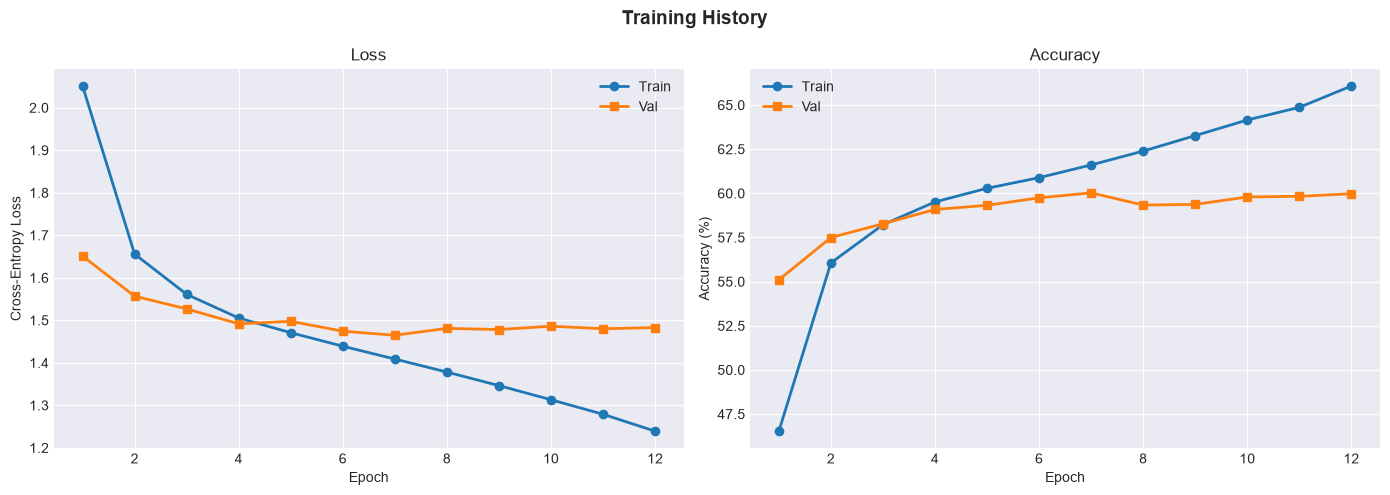

In [11]:
# ══════════════════════════════════════════════════════════════
#  Cell 11 — Training Curves
# ══════════════════════════════════════════════════════════════
plt.style.use("seaborn-v0_8-darkgrid")
epochs_ran = list(range(1, len(history["train_loss"]) + 1))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Training History", fontsize=14, fontweight="bold")

axes[0].plot(epochs_ran, history["train_loss"], "o-", label="Train", linewidth=2)
axes[0].plot(epochs_ran, history["val_loss"],   "s-", label="Val",   linewidth=2)
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-Entropy Loss")
axes[0].legend()

axes[1].plot(epochs_ran, [a*100 for a in history["train_acc"]], "o-", label="Train", linewidth=2)
axes[1].plot(epochs_ran, [a*100 for a in history["val_acc"]],   "s-", label="Val",   linewidth=2)
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
axes[1].legend()

plt.tight_layout()
plt.savefig("models/training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# ══════════════════════════════════════════════════════════════
#  Cell 12 — Save All Artifacts
# ══════════════════════════════════════════════════════════════
with open(CONFIG["word2idx_save_path"], "wb") as f:
    pickle.dump(WORD2IDX, f)

with open(CONFIG["label_enc_save_path"], "wb") as f:
    pickle.dump({"str2idx": STR2IDX, "idx2str": IDX2STR}, f)

config_snap = {k: str(v) if isinstance(v, Path) else v for k, v in CONFIG.items()}
config_snap["num_classes"] = NUM_CLASSES
with open("models/config_snapshot.json", "w") as f:
    json.dump(config_snap, f, indent=2)

print(" All artifacts saved:")
print(f"   Model weights  → {CONFIG['model_save_path']}")
print(f"   Vocabulary     → {CONFIG['word2idx_save_path']}")
print(f"   Label encoder  → {CONFIG['label_enc_save_path']}")
print(f"   Config         → models/config_snapshot.json")
print(f"   Training plot  → models/training_curves.png")
print("Completed!!")

 All artifacts saved:
   Model weights  → saved_model.pth
   Vocabulary     → models\word2idx.pkl
   Label encoder  → models\label_encoder.pkl
   Config         → models/config_snapshot.json
   Training plot  → models/training_curves.png
Completed!!
